In [1]:
%pip -q install requests pandas numpy scikit-learn matplotlib

In [2]:
from datetime import datetime, timezone
from getpass import getpass
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
FDC_SEARCH_URL = "https://api.nal.usda.gov/fdc/v1/foods/search"
RETRIEVED_AT_UTC = datetime.now(timezone.utc).isoformat(timespec="seconds")

try:
    from google.colab import userdata
    API_KEY = userdata.get("FDC_API_KEY")
except Exception:
    API_KEY = None

if not API_KEY:
    API_KEY = getpass("USDA FDC API key (input hidden): ").strip()
if not API_KEY:
    raise ValueError("กรุณาตั้ง FDC_API_KEY ใน Colab Secrets หรือกรอก API key")

print("Environment ready. API key is stored in memory and will not be displayed.")

USDA FDC API key (input hidden): ··········
Environment ready. API key is stored in memory and will not be displayed.


In [3]:
SEARCH_TERMS = [
    "chicken breast", "tofu", "brown rice", "egg", "salmon",
    "oats", "banana", "lentils", "spinach", "yogurt", "shrimp",
    "potato", "beans", "pork loin", "whole wheat bread",
    "sweet potato", "broccoli", "cod", "milk", "chickpeas",
]
DATA_TYPES = ["Foundation", "SR Legacy"]
PAGE_SIZE = 25
REQUEST_PAUSE_SECONDS = 0.15

nutrient_ids = {
    1008: "kcal",
    1003: "protein_g",
    1005: "carbs_g",
    1004: "fat_g",
    1093: "sodium_mg",
}

session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=3))

def search_fdc(term):
    response = session.post(
        FDC_SEARCH_URL,
        params={"api_key": API_KEY},
        json={"query": term, "dataType": DATA_TYPES, "pageSize": PAGE_SIZE},
        timeout=45,
    )
    response.raise_for_status()
    return response.json().get("foods", [])

rows = []
query_errors = []
for index, term in enumerate(SEARCH_TERMS, start=1):
    try:
        foods = search_fdc(term)
        for food in foods:
            nutrient_values = {
                item.get("nutrientId"): item.get("value")
                for item in food.get("foodNutrients", [])
                if item.get("nutrientId") in nutrient_ids
            }
            row = {
                "fdc_id": food.get("fdcId"),
                "description": food.get("description", ""),
                "data_type": food.get("dataType", ""),
                "query_term": term,
                "retrieved_at_utc": RETRIEVED_AT_UTC,
            }
            row.update({column: nutrient_values.get(nutrient_id) for nutrient_id, column in nutrient_ids.items()})
            rows.append(row)
        print(f"[{index:02d}/{len(SEARCH_TERMS)}] {term}: {len(foods)} results")
    except requests.RequestException as exc:
        query_errors.append({"query_term": term, "error": str(exc)})
        print(f"[{index:02d}/{len(SEARCH_TERMS)}] {term}: request failed ({type(exc).__name__})")
    time.sleep(REQUEST_PAUSE_SECONDS)

raw_df = pd.DataFrame(rows)
if raw_df.empty:
    raise RuntimeError("ไม่พบข้อมูลจาก FDC API; ตรวจ API key, internet connection และลองอีกครั้ง")

print(f"\nRetrieved {len(raw_df):,} search rows; failed queries: {len(query_errors)}")

[01/20] chicken breast: 25 results
[02/20] tofu: 25 results
[03/20] brown rice: 25 results
[04/20] egg: 25 results
[05/20] salmon: 25 results
[06/20] oats: 25 results
[07/20] banana: 25 results
[08/20] lentils: 10 results
[09/20] spinach: 25 results
[10/20] yogurt: 25 results
[11/20] shrimp: 19 results
[12/20] potato: 25 results
[13/20] beans: 25 results
[14/20] pork loin: 25 results
[15/20] whole wheat bread: 25 results
[16/20] sweet potato: 25 results
[17/20] broccoli: 21 results
[18/20] cod: 10 results
[19/20] milk: 25 results
[20/20] chickpeas: 12 results

Retrieved 447 search rows; failed queries: 0


In [4]:
display(raw_df.head(10))
print("Data types:")
display(raw_df["data_type"].value_counts(dropna=False).rename_axis("data_type").to_frame("rows"))

,fdc_id,description,data_type,query_term,retrieved_at_utc,kcal,protein_g,carbs_g,fat_g,sodium_mg
0,2759004,"Lunchmeat, chicken breast, sliced",Foundation,chicken breast,2026-11-08T11:52:46+00:00,NaN,16.4,3.100,2.46,NaN
1,171515,"Chicken breast tenders, breaded, uncooked",SR Legacy,chicken breast,2026-11-08T11:52:46+00:00,263.0,14.7,15.000,15.80,536.0
2,174608,"Chicken breast, roll, oven-roasted",SR Legacy,chicken breast,2026-11-08T11:52:46+00:00,134.0,14.6,1.790,7.65,883.0
3,2646170,"Chicken, breast, boneless, skinless, raw",Foundation,chicken breast,2026-11-08T11:52:46+00:00,NaN,22.5,0.000,1.93,65.8
4,2727569,"Chicken, breast, meat and skin, raw",Foundation,chicken breast,2026-11-08T11:52:46+00:00,NaN,21.4,-0.428,4.78,48.1
5,171514,"Chicken breast tenders, breaded, cooked, micro...",SR Legacy,chicken breast,2026-11-08T11:52:46+00:00,252.0,16.4,17.600,12.90,446.0
6,172945,"Oscar Mayer, Chicken Breast (honey glazed)",SR Legacy,chicken breast,2026-11-08T11:52:46+00:00,109.0,19.8,4.300,1.50,1440.0
7,173874,"Chicken breast, deli, rotisserie seasoned, sli...",SR Legacy,chicken breast,2026-11-08T11:52:46+00:00,98.0,17.4,2.920,1.86,1030.0
8,172962,"Chicken breast, fat-free, mesquite flavor, sliced",SR Legacy,chicken breast,2026-11-08T11:52:46+00:00,80.0,16.8,2.250,0.39,1040.0
9,172963,"Chicken breast, oven-roasted, fat-free, sliced",SR Legacy,chicken breast,2026-11-08T11:52:46+00:00,79.0,16.8,2.170,0.39,1090.0


Data types:


,rows
data_type,
SR Legacy,396
Foundation,51


In [5]:
required_columns = ["fdc_id", "description", "data_type", "kcal", "protein_g", "sodium_mg"]
missing_columns = sorted(set(required_columns) - set(raw_df.columns))
if missing_columns:
    raise KeyError(f"FDC response missing expected fields: {missing_columns}")

numeric_columns = ["kcal", "protein_g", "carbs_g", "fat_g", "sodium_mg"]
for column in numeric_columns:
    raw_df[column] = pd.to_numeric(raw_df[column], errors="coerce")

before_dedup = len(raw_df)
df = raw_df.dropna(subset=["fdc_id"]).drop_duplicates(subset=["fdc_id"]).copy()
deduplicated_count = before_dedup - len(df)
df = df.dropna(subset=["kcal", "protein_g", "sodium_mg"])
df = df[(df["kcal"] > 0) & (df["protein_g"] >= 0) & (df["sodium_mg"] >= 0)]
df = df.reset_index(drop=True)

print(f"Duplicate records removed: {deduplicated_count:,}")
print(f"Valid unique foods: {len(df):,}")
if len(df) < 30:
    raise RuntimeError(
        f"เหลือข้อมูลเพียง {len(df)} รายการ (ต้องการอย่างน้อย 30) "
        "ให้เพิ่มคำค้น ตรวจสอบ API key หรือดู response จาก FDC"
    )

Duplicate records removed: 5
Valid unique foods: 401


In [6]:
data_dictionary = pd.DataFrame([
    ("fdc_id", "รหัสรายการอาหารใน FoodData Central"),
    ("description", "ชื่ออาหารตาม FDC; เก็บเป็นข้อความต้นทาง"),
    ("data_type", "Foundation หรือ SR Legacy"),
    ("query_term", "คำค้นที่พบ record นี้ครั้งแรก"),
    ("kcal", "พลังงานตามค่าที่ส่งคืนจาก FDC"),
    ("protein_g", "โปรตีน หน่วยกรัม"),
    ("carbs_g", "คาร์โบไฮเดรต หน่วยกรัม"),
    ("fat_g", "ไขมัน หน่วยกรัม"),
    ("sodium_mg", "โซเดียม หน่วยมิลลิกรัม"),
    ("retrieved_at_utc", "เวลา snapshot ที่ดึงข้อมูล"),
], columns=["column", "description"])
display(data_dictionary)
display(df[numeric_columns].describe().T.round(2))

,column,description
0,fdc_id,รหัสรายการอาหารใน FoodData Central
1,description,ชื่ออาหารตาม FDC; เก็บเป็นข้อความต้นทาง
2,data_type,Foundation หรือ SR Legacy
3,query_term,คำค้นที่พบ record นี้ครั้งแรก
4,kcal,พลังงานตามค่าที่ส่งคืนจาก FDC
5,protein_g,โปรตีน หน่วยกรัม
6,carbs_g,คาร์โบไฮเดรต หน่วยกรัม
7,fat_g,ไขมัน หน่วยกรัม
8,sodium_mg,โซเดียม หน่วยมิลลิกรัม
9,retrieved_at_utc,เวลา snapshot ที่ดึงข้อมูล


,count,mean,std,min,25%,50%,75%,max
kcal,401.0,185.42,149.91,12.0,76.00,139.00,270.0,902.0
protein_g,401.0,10.97,11.34,0.0,2.94,8.00,14.7,81.1
carbs_g,401.0,21.54,24.81,0.0,2.40,11.70,31.3,92.7
fat_g,401.0,6.43,11.51,0.0,0.60,3.13,7.4,100.0
sodium_mg,401.0,241.98,463.91,0.0,23.00,78.00,354.0,7030.0


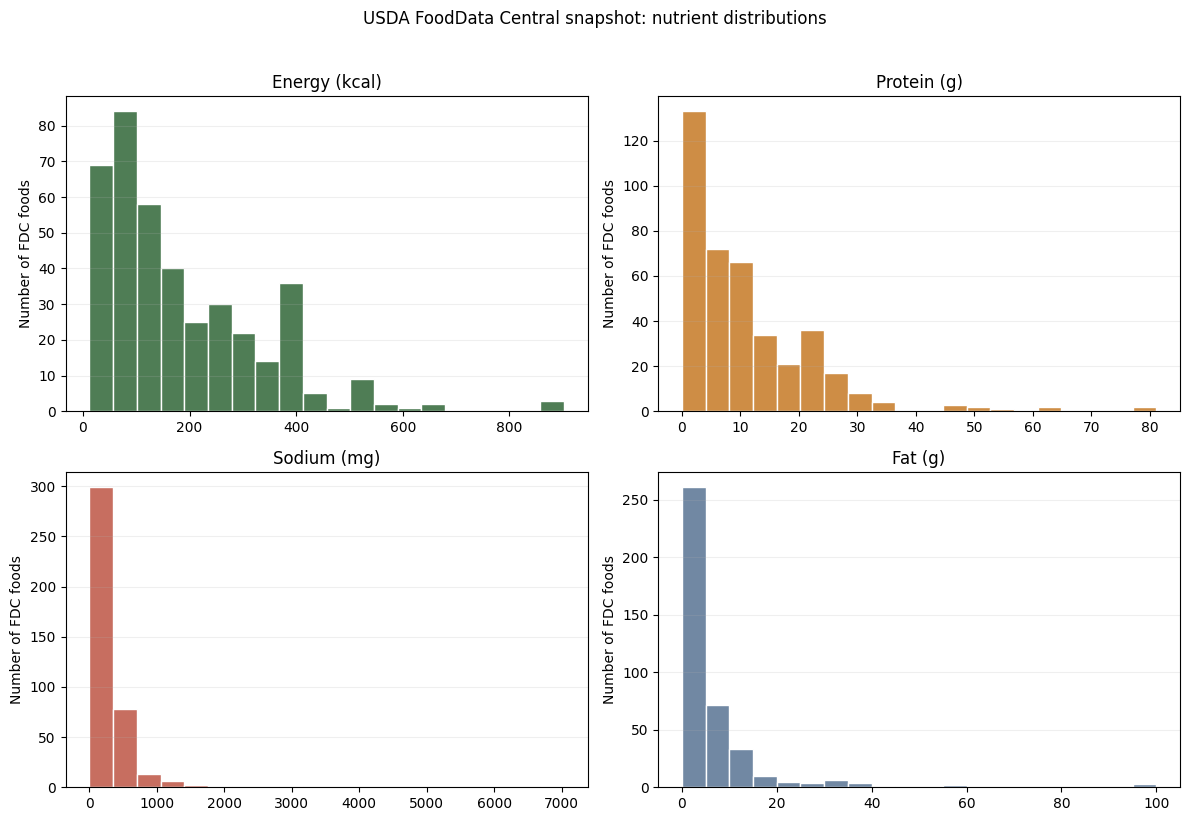

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column, title, color in [
    (axes[0, 0], "kcal", "Energy (kcal)", "#4f7d55"),
    (axes[0, 1], "protein_g", "Protein (g)", "#ce8d45"),
    (axes[1, 0], "sodium_mg", "Sodium (mg)", "#c76e60"),
    (axes[1, 1], "fat_g", "Fat (g)", "#7188a3"),
]:
    ax.hist(df[column].dropna(), bins=20, color=color, edgecolor="white")
    ax.set_title(title)
    ax.set_ylabel("Number of FDC foods")
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("USDA FoodData Central snapshot: nutrient distributions", y=1.02)
fig.tight_layout()
plt.show()

In [8]:
snapshot_path = Path("/content/usda_fooddata_central_sample.csv")
df.to_csv(snapshot_path, index=False)
print(f"Saved {snapshot_path.name} ({snapshot_path.stat().st_size:,} bytes)")
display(df[["fdc_id", "description", "data_type", *numeric_columns]].head(12))

Saved usda_fooddata_central_sample.csv (48,167 bytes)


,fdc_id,description,data_type,kcal,protein_g,carbs_g,fat_g,sodium_mg
0,171515,"Chicken breast tenders, breaded, uncooked",SR Legacy,263.0,14.7,15.00,15.80,536.0
1,174608,"Chicken breast, roll, oven-roasted",SR Legacy,134.0,14.6,1.79,7.65,883.0
2,171514,"Chicken breast tenders, breaded, cooked, micro...",SR Legacy,252.0,16.4,17.60,12.90,446.0
3,172945,"Oscar Mayer, Chicken Breast (honey glazed)",SR Legacy,109.0,19.8,4.30,1.50,1440.0
4,173874,"Chicken breast, deli, rotisserie seasoned, sli...",SR Legacy,98.0,17.4,2.92,1.86,1030.0
5,172962,"Chicken breast, fat-free, mesquite flavor, sliced",SR Legacy,80.0,16.8,2.25,0.39,1040.0
6,172963,"Chicken breast, oven-roasted, fat-free, sliced",SR Legacy,79.0,16.8,2.17,0.39,1090.0
7,171125,"Chicken, broiler, rotisserie, BBQ, breast, mea...",SR Legacy,175.0,26.4,0.09,7.67,329.0
8,171445,"Chicken, broiler, rotisserie, BBQ, breast, mea...",SR Legacy,144.0,28.0,0.00,3.57,328.0
9,171474,"Chicken, broilers or fryers, breast, meat and ...",SR Legacy,172.0,20.8,0.00,9.25,63.0


In [9]:
FEATURE_NAMES = [
    "budget_fit", "protein", "low_sodium",
    "preference_match", "calorie_fit", "popularity",
]
PROXY_WEIGHTS = np.array([0.15, 0.35, 0.25, 0.15, 0.10, 0.00], dtype=float)
TARGET_CALORIES = 500.0

train_foods, test_foods = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE,
)

def make_features(frame, seed):
    rng = np.random.default_rng(seed)
    kcal = frame["kcal"].to_numpy(dtype=float)
    protein_g = frame["protein_g"].to_numpy(dtype=float)
    sodium_mg = frame["sodium_mg"].to_numpy(dtype=float)
    return pd.DataFrame({
        "budget_fit": rng.uniform(0.25, 1.0, len(frame)),
        "protein": np.clip(protein_g / 35.0, 0.0, 1.0),
        "low_sodium": np.clip(1.0 - sodium_mg / 1800.0, 0.0, 1.0),
        "preference_match": rng.uniform(0.0, 1.0, len(frame)),
        "calorie_fit": np.clip(1.0 - np.abs(kcal - TARGET_CALORIES) / TARGET_CALORIES, 0.0, 1.0),
        "popularity": np.full(len(frame), 0.5),
    }, columns=FEATURE_NAMES, index=frame.index)

def make_proxy_target(features):
    return features.to_numpy() @ PROXY_WEIGHTS

X_train = make_features(train_foods, RANDOM_STATE)
X_test = make_features(test_foods, RANDOM_STATE + 1)
y_train = make_proxy_target(X_train)
y_test = make_proxy_target(X_test)

print(f"Train FDC records: {len(X_train):,} | test FDC records: {len(X_test):,}")
display(X_train.head())

Train FDC records: 320 | test FDC records: 81


,budget_fit,protein,low_sodium,preference_match,calorie_fit,popularity
18,0.830467,0.708571,0.847222,0.916348,0.520,0.5
203,0.579159,0.230286,0.982222,0.480910,0.166,0.5
351,0.893948,0.080286,0.986667,0.328361,0.052,0.5
275,0.773026,0.591429,0.969444,0.535435,0.340,0.5
63,0.320633,0.088286,0.997778,0.848560,0.294,0.5


In [10]:
proxy_definition = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "proxy_weight": PROXY_WEIGHTS,
    "interpretation": [
        "simulated fit to budget (FDC has no price)",
        "protein grams normalized by 35 g",
        "lower sodium receives higher score",
        "simulated match to user preference (no FDC feedback)",
        "closeness to a 500 kcal target",
        "constant neutral value; no FDC popularity data",
    ],
})
display(proxy_definition)

,feature,proxy_weight,interpretation
0,budget_fit,0.15,simulated fit to budget (FDC has no price)
1,protein,0.35,protein grams normalized by 35 g
2,low_sodium,0.25,lower sodium receives higher score
3,preference_match,0.15,simulated match to user preference (no FDC fee...
4,calorie_fit,0.10,closeness to a 500 kcal target
5,popularity,0.00,constant neutral value; no FDC popularity data


In [11]:
model = make_pipeline(StandardScaler(), Ridge(alpha=0.05))
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
baseline_pred = make_proxy_target(X_test)

def ndcg_at_k(y_true, y_score, k=10):
    y_true = np.asarray(y_true, dtype=float)
    y_score = np.asarray(y_score, dtype=float)
    k = min(k, len(y_true))
    if k == 0:
        return float("nan")
    order = np.argsort(y_score)[::-1][:k]
    ideal = np.argsort(y_true)[::-1][:k]
    discounts = np.log2(np.arange(2, k + 2))
    dcg = np.sum((2 ** y_true[order] - 1) / discounts)
    idcg = np.sum((2 ** y_true[ideal] - 1) / discounts)
    return float(dcg / idcg) if idcg else 0.0

try:
    from scipy.stats import spearmanr
    spearman = float(spearmanr(y_test, y_pred).statistic)
except Exception:
    spearman = float("nan")

def metric_row(name, truth, prediction):
    return {
        "model": name,
        "MAE": mean_absolute_error(truth, prediction),
        "RMSE": mean_squared_error(truth, prediction) ** 0.5,
        "R²": r2_score(truth, prediction),
        "NDCG@10": ndcg_at_k(truth, prediction, 10),
    }

metrics_df = pd.DataFrame([
    metric_row("Ridge (trained)", y_test, y_pred),
    metric_row("Proxy formula baseline", y_test, baseline_pred),
])
display(metrics_df.round(4))
print(f"Spearman rank correlation (trained model vs proxy): {spearman:.4f}")

,model,MAE,RMSE,R²,NDCG@10
0,Ridge (trained),0.0,0.0,1.0,1.0
1,Proxy formula baseline,0.0,0.0,1.0,1.0


Spearman rank correlation (trained model vs proxy): 1.0000


In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_mae = -cross_val_score(
    model, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error",
)
print("5-fold CV MAE on training proxy labels:")
print(f"mean={cv_mae.mean():.4f}, std={cv_mae.std():.4f}")

5-fold CV MAE on training proxy labels:
mean=0.0000, std=0.0000


,feature,proxy_weight,ridge_weight
1,protein,0.35,0.3499
2,low_sodium,0.25,0.2499
3,preference_match,0.15,0.1500
0,budget_fit,0.15,0.1500
4,calorie_fit,0.10,0.1000
5,popularity,0.00,0.0000


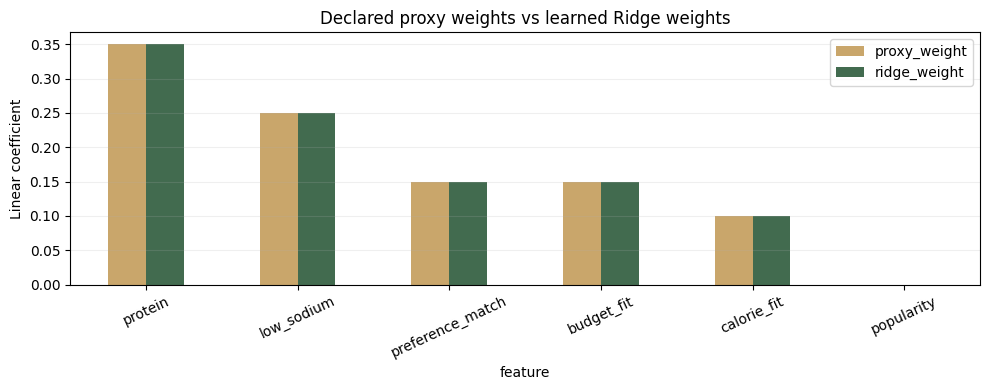

In [13]:
ridge = model.named_steps["ridge"]
scaler = model.named_steps["standardscaler"]
export_weights = ridge.coef_ / scaler.scale_
export_bias = ridge.intercept_ - np.sum(ridge.coef_ * scaler.mean_ / scaler.scale_)

coefficient_df = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "proxy_weight": PROXY_WEIGHTS,
    "ridge_weight": export_weights,
}).sort_values("ridge_weight", ascending=False)
display(coefficient_df.round(4))

ax = coefficient_df.set_index("feature")[["proxy_weight", "ridge_weight"]].plot(
    kind="bar", figsize=(10, 4), color=["#c9a66b", "#426b4f"],
)
ax.set_title("Declared proxy weights vs learned Ridge weights")
ax.set_ylabel("Linear coefficient")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [14]:
test_results = test_foods[["fdc_id", "description", "data_type", "kcal", "protein_g", "sodium_mg"]].copy()
test_results["proxy_target"] = y_test
test_results["ridge_score"] = y_pred
test_results["baseline_score"] = baseline_pred
print("Top 10 held-out FDC foods by learned proxy score:")
display(test_results.sort_values("ridge_score", ascending=False).head(10).reset_index(drop=True))

Top 10 held-out FDC foods by learned proxy score:


,fdc_id,description,data_type,kcal,protein_g,sodium_mg,proxy_target,ridge_score,baseline_score
0,329490,"Egg, whole, dried",Foundation,575.0,48.1,485.0,0.849731,0.849686,0.849731
1,172188,"Egg, whole, dried",SR Legacy,592.0,48.0,476.0,0.832156,0.832112,0.832156
2,172450,"Tofu, dried-frozen (koyadofu)",SR Legacy,477.0,52.5,6.0,0.826100,0.826055,0.826100
3,173428,"Egg, yolk, dried",SR Legacy,669.0,33.6,149.0,0.814406,0.814364,0.814406
4,173460,"Protein supplement, milk based, Muscle Milk Li...",SR Legacy,396.0,50.0,250.0,0.770564,0.770528,0.770564
5,173429,"Egg substitute, powder",SR Legacy,444.0,55.5,800.0,0.764182,0.764152,0.764182
6,175180,"Crustaceans, shrimp, cooked",SR Legacy,99.0,24.0,111.0,0.750114,0.750076,0.750114
7,167839,"Pork, fresh, loin, top loin (chops), boneless,...",SR Legacy,155.0,21.6,48.0,0.743984,0.743946,0.743984
8,167826,"Pork, fresh, loin, center loin (chops), bone-i...",SR Legacy,242.0,28.2,73.0,0.742208,0.742175,0.742208
9,167841,"Pork, fresh, loin, top loin (chops), boneless,...",SR Legacy,196.0,26.6,44.0,0.732924,0.732888,0.732924


In [15]:
artifact = {
    "version": "1.1-usda-proxy",
    "features": FEATURE_NAMES,
    "weights": [float(value) for value in export_weights],
    "bias": float(export_bias),
    "trained": True,
    "note": "Ridge model trained on USDA FDC nutrient records with a declared weak-supervision proxy; not user ratings.",
}

output_dir = Path("/content")
model_path = output_dir / "model.json"
model_path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding="utf-8")

print("Feature contract:", artifact["features"])
print("Weights:", [round(value, 4) for value in artifact["weights"]])
print("Bias:", round(artifact["bias"], 4))
print("Trained:", artifact["trained"])
print("\nSaved:", model_path)
print(model_path.read_text(encoding="utf-8"))

Feature contract: ['budget_fit', 'protein', 'low_sodium', 'preference_match', 'calorie_fit', 'popularity']
Weights: [0.15, 0.3499, 0.2499, 0.15, 0.1, 0.0]
Bias: 0.0001
Trained: True

Saved: /content/model.json
{
  "version": "1.1-usda-proxy",
  "features": [
    "budget_fit",
    "protein",
    "low_sodium",
    "preference_match",
    "calorie_fit",
    "popularity"
  ],
  "weights": [
    0.14997255002530369,
    0.3499408013542614,
    0.24994624883103103,
    0.1499813954588553,
    0.09999380212045789,
    0.0
  ],
  "bias": 9.298557531312035e-05,
  "trained": true,
  "note": "Ridge model trained on USDA FDC nutrient records with a declared weak-supervision proxy; not user ratings."
}


In [16]:
from google.colab import files

files.download(str(model_path))
files.download(str(snapshot_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>